In [1]:
# Move to project directory
import os
os.chdir("/home/mdarif/MLOPS/customer-churn-prediction-system")
print(os.getcwd())

/home/mdarif/MLOPS/customer-churn-prediction-system


# Table of Content

**1. Introduction**

**2. Data Loading and Initial Exploration**
- 2.1 Importing Libraries
- 2.2 Loading Dataset
- 2.3 Initial Data Inspection
- 2.4 Missing Value Analysis
- 2.5 Duplicate Analysis
- 2.6 Data Manipulation

**3. Exploratory Data Analysis (EDA)**
- 3.1 Overview
- 3.2 Target
- 3.3 Demographic Features
- 3.4 Service Features
- 3.5 Account Features
- 3.6 Billing Features

**4. Feature Relationships**
- 4.1 Partner and Dependents
- 4.2 Contract and Tenure
- 4.3 MonthlyCharges and TotalCharges
- 4.4 MonthlyCharges and InternetService
- 4.5 Contract and PaymentMethod
- 4.6 Tenure and Churn
- 4.7 Contract and Churn
- 4.8 InternetService and Churn
- 4.9 MonthlyCharges and Churn
- 4.10 TotalCharges and Churn
- 4.11 SeniorCitizen and Churn
- 4.12 Correlation Matrix
- 4.13 EDA Conclusions

## 1. Introduction

- Customer churn is an important problem in the telecommunications industry churn happens when a customer stops using a company's service. A high churn rate can lead to lower revenue higher customer acquisition cost, and lower customer lifetine value.

- Keeping existing customer is generally more cost-effective than acquiring new ones. When customers leaves early, the company may lose the expected revenue from those customers. Offering discounts and special deals to retain customers can also affect profitability.

- Machine learning can helo identify customers who are more likely to churn by analyzing customer information, service usage, contract details and billing information we can find patterns that may be related to customer churn.

- In this project we will explore the customer data, identify the factors related to churn and build a machine learning model to predict whether a customer is likely to churn.

## 2. Data Loading and Initial Exploration

#### Feature Descriptions:

- **customerID** - unique customer identifier.
- **gender** - customer gender.
- **SeniorCitizen** - whether the customer is a senior citizen.
- **Partner** - whether the customer has a partner.
- **Dependents** - whether the customer has dependents.
- **tenure** - number of months the customer has been using the company's services.
- **PhoneService** - whether phone service is enabled.
- **MultipleLines** - whether multiple phone lines are enabled.
- **InternetService** - type of the customer's internet service.
- **OnlineSecurity** - whether the online security service is enabled.
- **OnlineBackup** - whether the online backup service is enabled.
- **DeviceProtection** - whether the device protection service is enabled.
- **TechSupport** - whether technical support is enabled.
- **StreamingTV** - whether the streaming TV service is enabled.
- **StreamingMovies** - whether the streaming movies service is enabled.
- **Contract** - type of customer contract.
- **PaperlessBilling** - whether the customer uses paperless billing.
- **PaymentMethod** - payment method.
- **MonthlyCharges** - customer's monthly charges.
- **TotalCharges** - customer's total charges over the entire service period.
- **Churn** - target feature: whether the customer stopped using the company's services.

### 2.1 Importing Libraries

In [2]:
# Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from kaggle.api.kaggle_api_extended import KaggleApi

In [3]:
# Load environment variables
load_dotenv()

True

### 2.2 Loading Dataset

In [4]:
# Download dataset from kaggle
kaggle_username = os.getenv("KAGGLE_USERNAME")
kaggle_api_token = os.getenv("KAGGLE_API_TOKEN")

if not kaggle_username or not kaggle_api_token:
  raise ValueError("kaggle_username and kaggle_api_token must be set.")

api = KaggleApi()
api.authenticate()

dataset = "blastchar/telco-customer-churn"

download_dir = "/tmp/customer_churn"

os.makedirs(download_dir, exist_ok=True)

api.dataset_download_files(
  dataset=dataset,
  path=download_dir,
  unzip=True
)

file_path = os.path.join(
  download_dir,
  "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print(file_path)

Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
/tmp/customer_churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


### 2.3 Initial Data Inspection

In [5]:
# Load the dataset and display the first five rows
df = pd.read_csv(file_path)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Display the last five rows
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [7]:
# Display dataset columns
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [8]:
# Display dataset shapes
df.shape

(7043, 21)

In [9]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 2.4 Missing Values Analysis

In [10]:
# Display the missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### 2.4 Duplicate Analysis

In [11]:
# Check for exact duplicate rows
duplicate_count = df.duplicated().sum()
duplicate_rows = df[df.duplicated(keep=False)]

print(f"Duplicate rows: {duplicate_count}")
display(duplicate_rows)

Duplicate rows: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [12]:
# Check duplicate features for different target values
feature_columns = df.columns.drop("Churn")

duplicate_features =df[
    df.duplicated(subset=feature_columns, keep=False)
].sort_values(by=list(feature_columns))


target_counts = (
    duplicate_features.groupby(list(feature_columns))["Churn"].nunique()
)

conflicting_duplicates = target_counts[target_counts > 1]
print(f"Conflicting duplicate groups: {len(conflicting_duplicates)}")

Conflicting duplicate groups: 0


### 2.5 Data Manipulation

In [13]:
# Encode the target variable as binary values
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [14]:
# Convert TotalCharges to a numeric data type
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [15]:
# Check the data type after conversion
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [16]:
# Check the missing values of each columns
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

The dataset contains 11 missing values in TotalCharges while other columns have no missing values. 
These missing values are likely related to cutomer with zero tenure meaning they have just started 
their sevice and have not yet accumulated any total charges. Next, we use describe() to examine the 
statistical summary and destribution of the numerical featues.

In [17]:
# Define numerical columns for descriptive analysis
numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

# Display the selected numerical columns
print(f"Numerical Columns: {', '.join(numerical_columns)}")

Numerical Columns: tenure, MonthlyCharges, TotalCharges


In [18]:
# Display descriptive statistics for numerical features
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


Based on describe() we can meke the following observations:

- tenure has a minimum value of 0 which means some customers have recently started their service. We should check the customer seperately the ones with missing TotalCharges.

- For TotalCharges the mean (2283.30) is higher than the median(1397.48). This suggests that the data is right-skewed with some customers having much higher total charges than most others. The standard deviation (2266.77) is also relatively high showing that the total charges vary considerably across customers.

In [19]:
# Distplay customers with zero tenure to inspect to missing TotalCharges values
df[df["tenure"] == 0]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,0
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,0
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,0
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,0
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,0
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,0
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,0
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,0
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,0
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,0


All missing values in TotalCharges belongs to customers with tenure = 0. Since there are only 11 such rows we can remove them without affecting he dataset much. We also remove customerID because it is a unique identifier and does not provide useful information for the model.

In [20]:
# Remvoe rows with zero tenure and missing TotalCharges
df = df.drop(df[df["tenure"] == 0].index)

In [21]:
# Check the number of duplicated rows
df.duplicated().sum()

0

In [22]:
# Remove the unique customer identifier
df = df.drop("customerID", axis=1)

## 3. Exploratory Data Analysis (EDA)

### 3.1 Overview

For the EDA we group the features into a few categories. This makes it easier to analyze the data and see how different types of customer information are related to churn.

- **Demographic**: `gender`, `SeniorCitizen`, `Partner`, `Dependents`

- **Service**: `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` 

- **Account**: `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`

- **Billing**: `MonthlyCharges`, `TotalCharges`

In [23]:
# Define Demographic features
demographic_features = [
  "gender",
  "SeniorCitizen",
  "Partner",
  "Dependents"
]

# Define Service-related features
service_features = [
  "PhoneService",
  "MultipleLines",
  "InternetService",
  "OnlineSecurity",
  "OnlineBackup",
  "DeviceProtection",
  "TechSupport",
  "StreamingTV",
  "StreamingMovies"
]

# Define Account-related features
account_features = [
  "tenure",
  "Contract",
  "PaperlessBilling",
  "PaymentMethod"
]

# Define Billing-related features
billing_features =[
  "MonthlyCharges",
  "TotalCharges"
]

### 3.2 Target (Churn)

First, we look at the distribution of the target variable Churn.

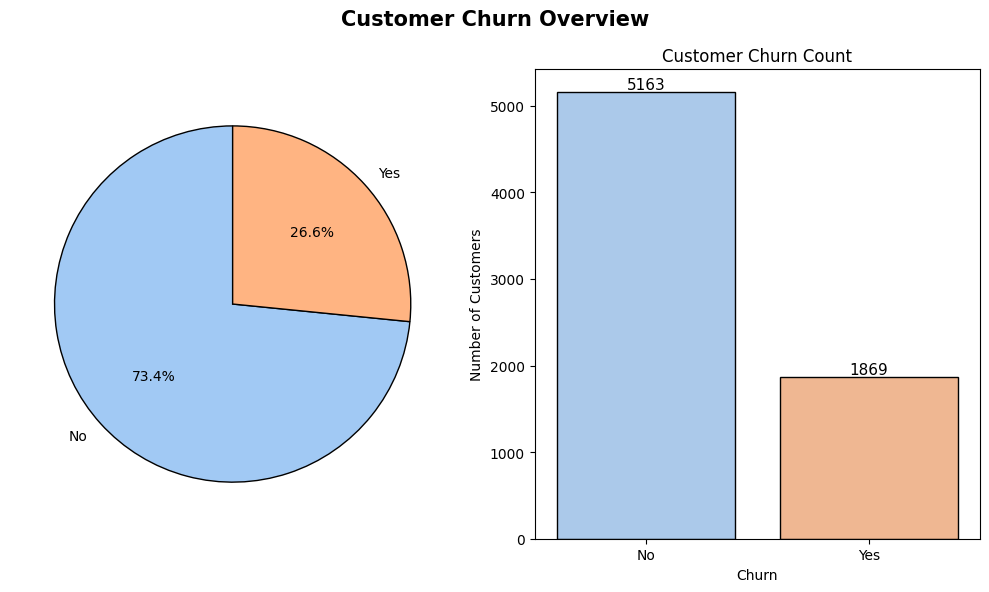

In [24]:
# Count the number of customers in each churn category
churn_stats = df["Churn"].value_counts()

# Create side-by-side plots for churn distribution
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 6))
colors = sns.color_palette("pastel", df["Churn"].nunique())

# Display churn distribution as a pie chart
ax[0].pie(
  churn_stats,
  labels=["No", "Yes"],
  autopct="%1.1f%%",
  startangle=90,
  colors=colors,
  wedgeprops={"edgecolor": "black", "linewidth": 1}
)

# Display churn distribution as a count plot
sns.countplot(
  data=df,
  x="Churn",
  hue="Churn",
  palette="pastel",
  edgecolor="black",
  legend=False,
  ax=ax[1]
)

# Add value labels above the bars
for container in ax[1].containers:
  ax[1].bar_label(container, fontsize=11, padding=0)

# Customize the count plot
ax[1].set_title("Customer Churn Count")
ax[1].set_xlabel("Churn")
ax[1].set_ylabel("Number of Customers")
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(["No", "Yes"])

fig.suptitle("Customer Churn Overview", fontsize=15, fontweight="bold")

# Adjust spacing between subplots
plt.tight_layout();

### Observation

The dataset shows a noticeable class imbalance 73.4% continued using and company's service while 26.6% of churned. This is important to take into account when training and evaluating models, since the accuracy metric in this situation may provide an overly optimistic view of classification performance.

### 3.3 Demographic features

Next, we look at the demographic features of customers.

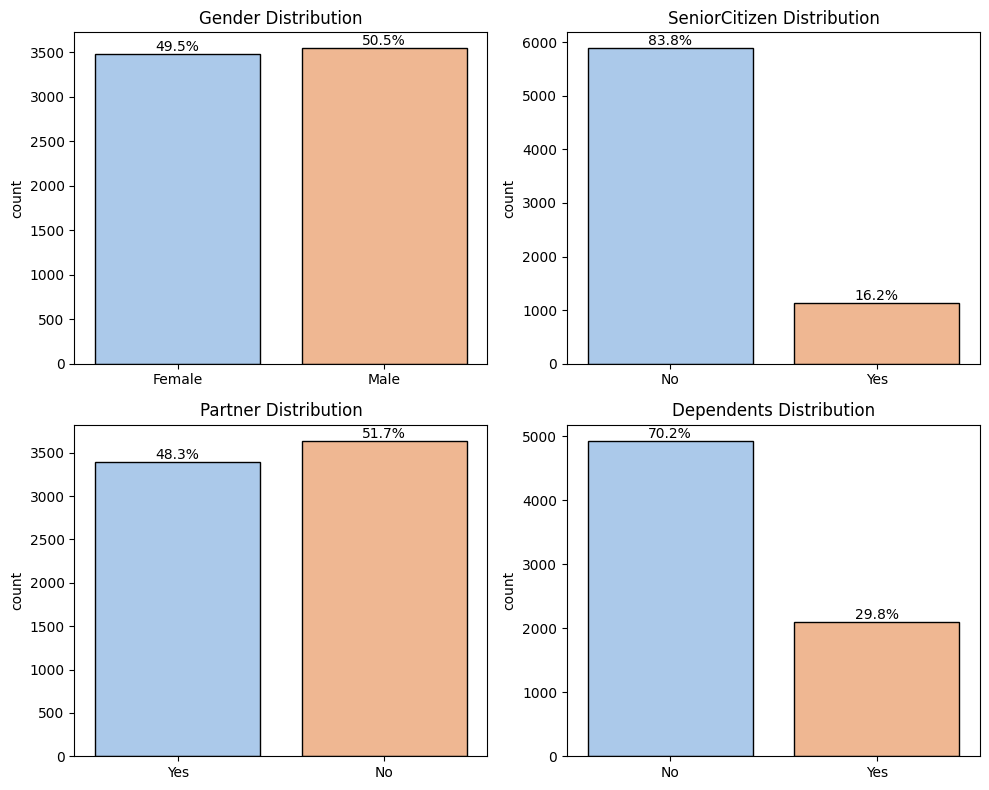

In [25]:
# Create a 2x2 grid for demographic feature distributions
fig, axes = plt.subplots(nrows=2, ncols=2,figsize=(10, 8))

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Plot the distribution of each demographic feature
for ax, feature in zip(axes, demographic_features):
    sns.countplot(
        data=df,
        x=feature,
        hue=feature,
        palette="pastel",
        edgecolor="black",
        legend=False,
        ax=ax
    )

    # Add percentage labels above the bars
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{x / len(df) * 100:.1f}%" for x in container.datavalues],
            fontsize=10
        )

    # Customize plot titles and axis labels
    ax.set_title(f"{feature.capitalize()} Distribution")
    ax.set_xlabel('')


    # Replace binary values with readable labels for SeniorCitizen
    if feature == "SeniorCitizen":
        ax.set_title(f"{feature} Distribution")
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["No", "Yes"])

# Adjust spacing between subplots
plt.tight_layout();

### Observation

- The gender and Partner features are fairly balanced.
- Seniorcitizen and Dependents are more unevenly distributed.
- Senior citizens make up around 16.2% of the customers.
- Most of the cutomers don't have dependents customers without dependents account for 70.2% while 29.8% have dependents.

It is also useful to look at the relationships between Partner and Dependents as these two features may be related. 

### 3.4 Service Features

Next, we look at the services, customers are using and see which ones are more common and which ones are less common.

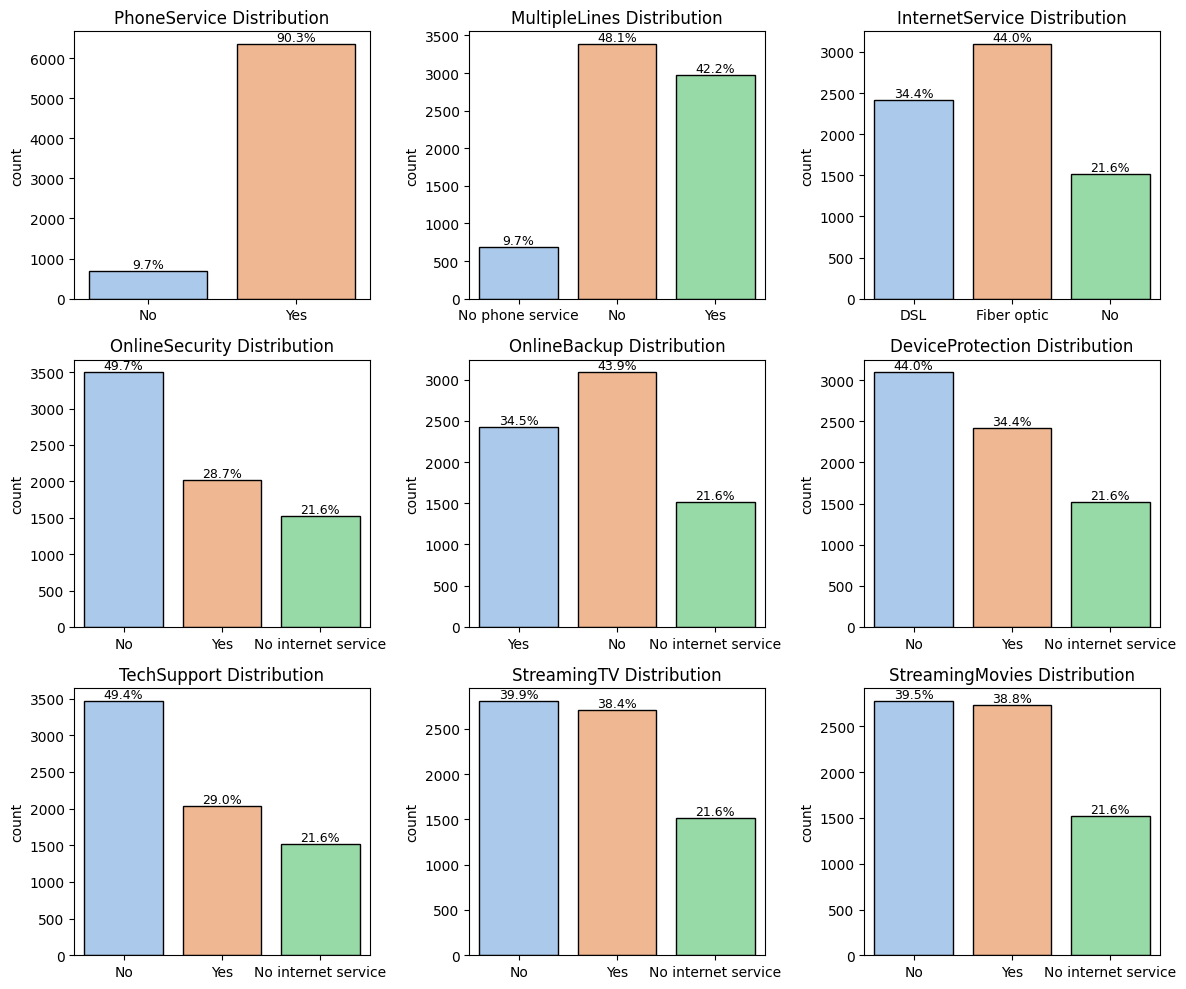

In [26]:
# Create 3x3 grid for service feature ditributions
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 10))

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Plot the distribution of each service feature
for ax, feature in zip(axes, service_features):
  sns.countplot(
    data=df,
    x=feature,
    hue=feature,
    palette="pastel",
    edgecolor="black",
    legend=False,
    ax=ax
  )

  # Add percentage labels above the bars
  for container in ax.containers:
    ax.bar_label(
      container,
      labels=[f"{x / len(df) * 100:.1f}%" for x in container.datavalues],
      fontsize=9
    )

  # Customize plot titles and axes plots
  ax.set_title(f"{feature} Distribution")
  ax.set_xlabel("")

# Adjust spacing btween subplots
plt.tight_layout();

### Observation

- PhoneService and Multipltelines contain some overlapping information. The No phone service category in MultipleLines already tells us that the customer don't have phone service. We can check during feature selection whether both features are needed.

- Most customers have internet service. Fiber optic is the most common type at 44.0% followed by DSL at 34.4% about 21.6% don't have internet service.

- For additional internet service such as OnlineSecurity, TechSupport, DeviceProtection and OnlineBackup many customers don't have these services.In comparison StreamingTV and StreamingMovies have more balanced distribution.

### 3.5 Account Features

The tenure distribution shows how long customers have been using the company's services.

Text(0, 0.5, 'Number of Customers')

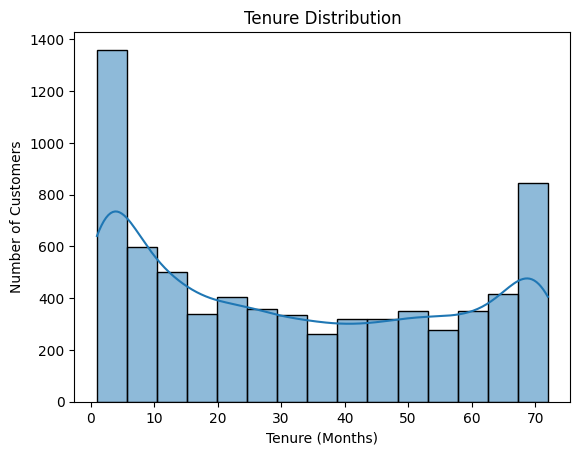

In [27]:
# Plot the distribution of customer tenure
sns.histplot(
  data=df,
  x="tenure",
  kde=True,
  edgecolor="black"
)

plt.title("Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

### Observation

The tenure distribution shows that many customers have either a short or a long service period. This may be related to the type of contract. Customers with long term contracts may stay with the company for a longer time while month to month customers may leave sooner. We wil explore tenure and contract separately. 

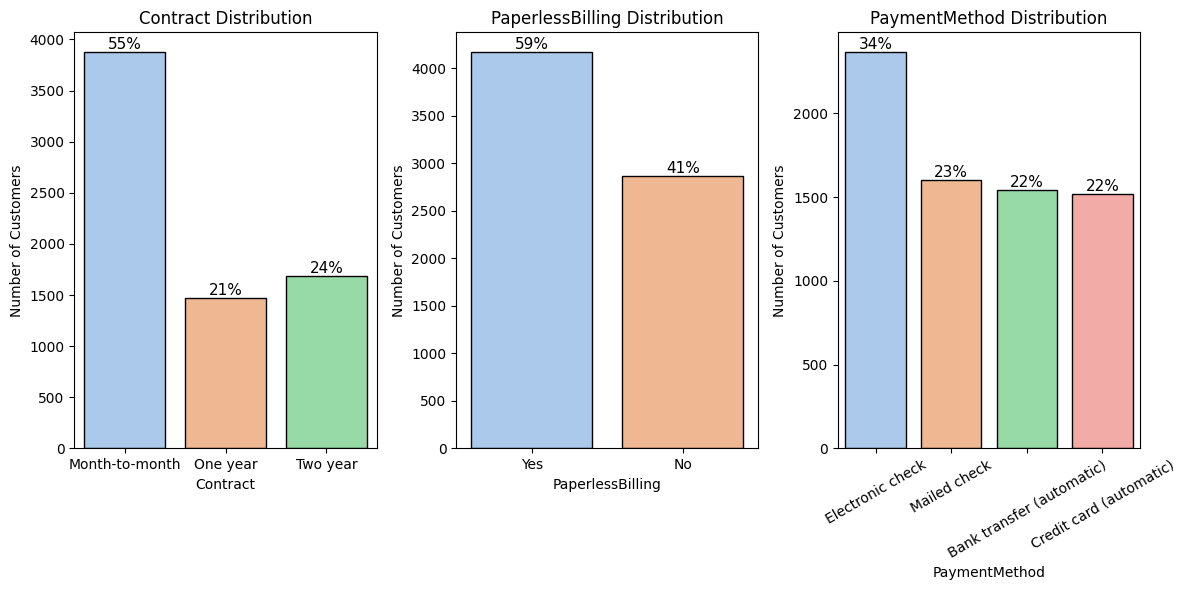

In [28]:
# Create side-by-side for account-related categorical features
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 6))

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Plot the distribution of each account feature
for ax, feature in zip(axes, account_features[1:]):
  ax = sns.countplot(
    data=df,
    x=feature,
    hue=feature,
    palette="pastel",
    edgecolor="black",
    legend=False,
    ax=ax
  )

  # Add percentage labels above the bars
  for container in ax.containers:
    ax.bar_label(
      container,
      labels=[f"{x / len(df) * 100:.0f}%" for x in container.datavalues],
      fontsize=11
    )

  # Rotate PaymentMethod labels for better readability
  if feature == "PaymentMethod":
    ax.tick_params(axis="x", rotation=30)

  # Customize plot titles and axix labels
  ax.set_title(f"{feature} Distribution")
  ax.set_ylabel("Number of Customers")

# Adjust spacing between subplots
plt.tight_layout();

### 3.6 Billing Features

We now look at the two billing variables MonthlyCharges & TotalCharges.

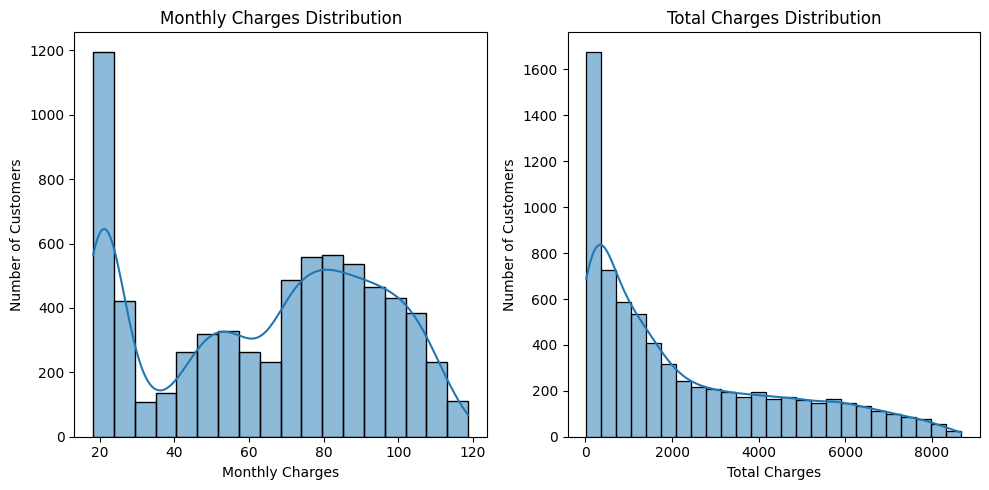

In [29]:
# Create side-by-side plots for billing feature distributions
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

# plot the distribution of monthly charges
# (no palette here — palette needs a hue variable, and there isn't one for
# these plots, which is what triggered the "Ignoring palette" warning before)
sns.histplot(
  data=df,
  x="MonthlyCharges",
  kde=True,
  edgecolor="black",
  ax=ax[0]
)

# plot the distribution of total charges
sns.histplot(
  data=df,
  x="TotalCharges",
  kde=True,
  edgecolor="black",
  ax=ax[1]
)

# Customize the monthly charges plot
ax[0].set_title("Monthly Charges Distribution")
ax[0].set_xlabel("Monthly Charges")
ax[0].set_ylabel("Number of Customers")

# Customize the total charges plot
ax[1].set_title("Total Charges Distribution")
ax[1].set_xlabel("Total Charges")
ax[1].set_ylabel("Number of Customers")

# Adjust spacing between subplots
plt.tight_layout();

### Observation

The MonthlyCharges distribution shows different groups of values where some ranges have more customers than others this could be related to the different services customers use but we cannot confirm the exact reason from this visualization alone the relationship between MonthlyCharges InternetService and other service related features should be checked seperately later.

## 4. Feature Relationships

The univariate analysis showed some possible relationships between the features so now we look at these relationships in more detail.

### 4.1 Partner and Dependents

We first compare partner status with whether customers have dependents.

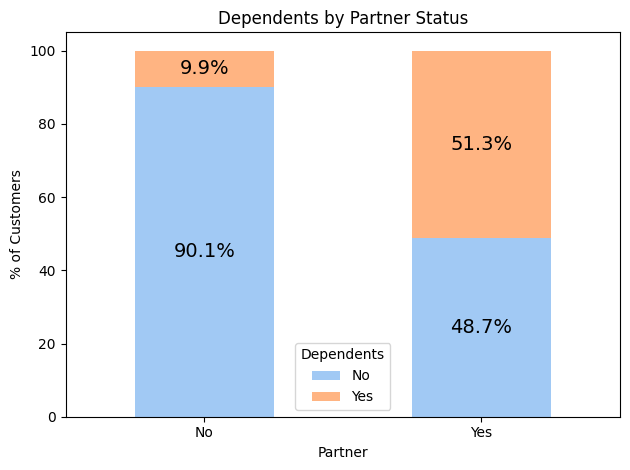

In [30]:
# Create a normalized contigency table for Partner and Dependents
cross = pd.crosstab(
  df["Partner"],
  df["Dependents"],
  normalize="index"
) * 100

# Plot the percentage distributions of Dependents by Partner status
ax = cross.plot(
  kind="bar",
  stacked=True,
  color=sns.color_palette("pastel", 2)
)

# Add percentage labels inside each stacked bar
for container in ax.containers:
  ax.bar_label(
    container,
    labels=[f"{x:.1f}%" for x in container.datavalues],
    label_type="center",
    fontsize=14
  )

# Customize plot title, axis labels and labels
ax.set_title("Dependents by Partner Status")
ax.set_xlabel("Partner")
ax.set_ylabel("% of Customers")
ax.legend(title="Dependents")

# Keep x-axis labels horizontal and adjust spacing between subplots
plt.xticks(rotation=0)
plt.tight_layout();

### Observation

Among customers without a partner around 90.1% do not have dependents while only about 9.9% have them for customers with a partner split is almost equal with 51.3% having dependents and 48.7% not having them this shows that customers with a partner are more likely to have dependents.

### 4.2 Contract and Tenure

We compare tenure across the three contract types to see how contract type is related to customer tenure.

Text(0, 0.5, 'Tenure (Months)')

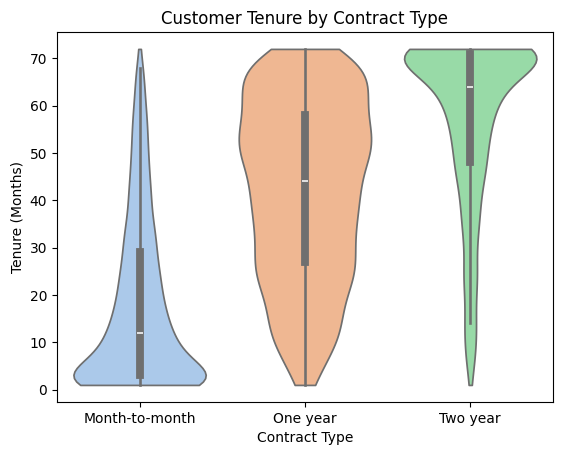

In [31]:
# Compare customer tenure across different contract types
sns.violinplot(
  data=df,
  x="Contract",
  y="tenure",
  hue="Contract",
  palette="pastel",
  cut=0
)

# Customize the plot title and axis labels
plt.title("Customer Tenure by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Tenure (Months)")

### Observation

There is a clear relationship between contract type and tenure as customers with month-to-month contract generally have shorter tenure while customers with two-year of contracts tend to stay with the company for longer periods and one-year contracts fall in between with a wider range of tenure values which supports our earlier observations that contract type and tenure are closely related but this doesn't mean that one directly causes the others.

### 4.3 Monthly and Total Charges by Tenure

We next look at how MonthlyCharges and tenure are reated to the overall TotalCharges.

Text(0, 0.5, 'Total Charges')

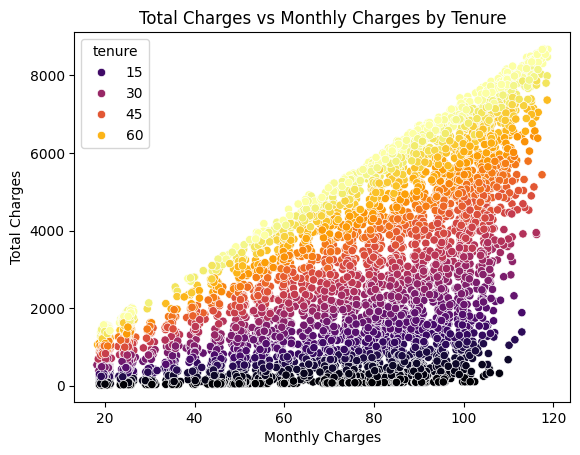

In [32]:
# Create the relationship between monthly and total charges by tenure
sns.scatterplot(
  data=df,
  x="MonthlyCharges",
  y="TotalCharges",
  hue="tenure",
  palette="inferno"
)

# Customize the plot title and axis labels
plt.title("Total Charges vs Monthly Charges by Tenure")
plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")

### Observation

Higher MonthlyCharges generally lead to higher TotalCharges and customers with longer tenure also tend to have higher TotalCharges because they have been the company for a longer period.

###  4.4 MonthlyCharges and InternetService

Earlier analysis suggested that MonthlyCharges may be different for each internel service type so we compare MonthlyCharges across the different InternetService categories.

Text(0, 0.5, 'Monthly Charges')

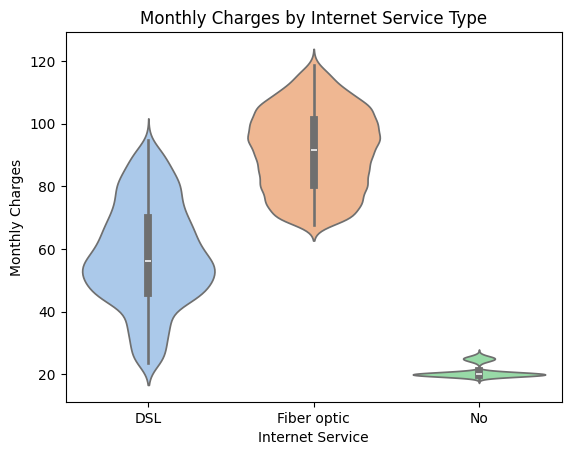

In [33]:
# Compare monthly charges across different internet service types
sns.violinplot(
  data=df,
  x="InternetService",
  y="MonthlyCharges",
  hue="InternetService",
  palette="pastel",
  legend=False
)

# Customize plot title and axis labels
plt.title("Monthly Charges by Internet Service Type")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Charges")

### Observation

MonthlyCharges are quite different across the internet service types with customers without internet service having the lowest charges at around 20 while DSL customers have charges mostly between 20 and 90 with many customers around 50 to 60. Fiber optic customers generally have higher charges with most values falling between 70 and 110. Overall Fiber optic customers have the MonthlyCharges compared with the other groups.

### 4.5 Contract and PaymentMethod

We also compare different contract types across payment methods to see if there is any relationship between them.

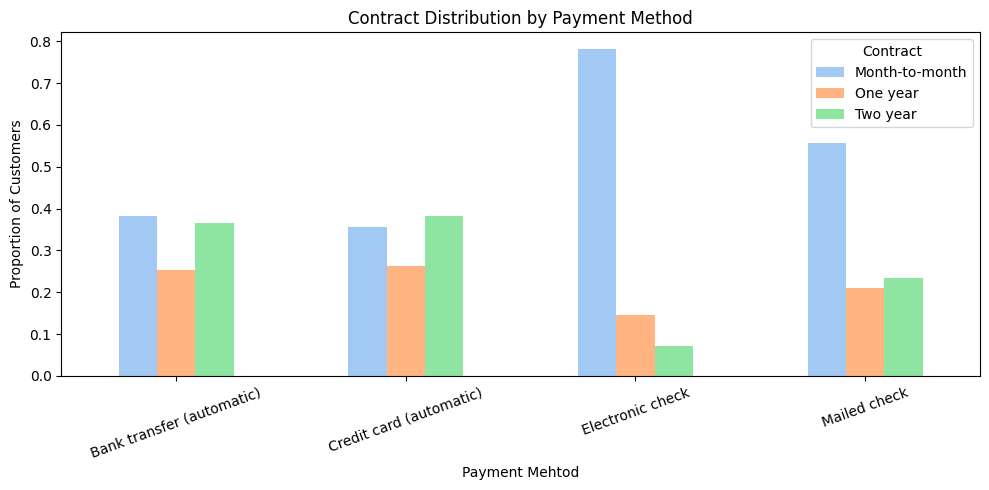

In [34]:
# Create a normalized contingency table for PaymentMethod and Contract
cross = pd.crosstab(
  df["PaymentMethod"],
  df["Contract"],
  normalize="index"
)

# Plot Contract distribution within each PaymentMethod
ax = cross.plot(
  kind="bar",
  figsize=(10, 5),
  color=sns.color_palette("pastel", 3)
)

# Customize the plot title and axis lebels
ax.set_title("Contract Distribution by Payment Method")
ax.set_xlabel("Payment Mehtod")
ax.set_ylabel("Proportion of Customers")
ax.legend(title="Contract")

# Rotate x-labels and adjust spacing between subplots
plt.xticks(rotation=20)
plt.tight_layout();

### Observation

The pattern is especially clear for Electronic check where around 78% of customers have month-to-month contracts. For the other payment methods the contract types are more evenly distributed which shows that payment method and contract type are related.

### 4.6 Tenure and Churn

We are compare the tenure of churned and retained customers to see if the length of time a customer stays with the company is related to Churn.

([<matplotlib.axis.XTick at 0x79e8589e5590>,
 [Text(0, 0, 'No'), Text(1, 0, 'Yes')])

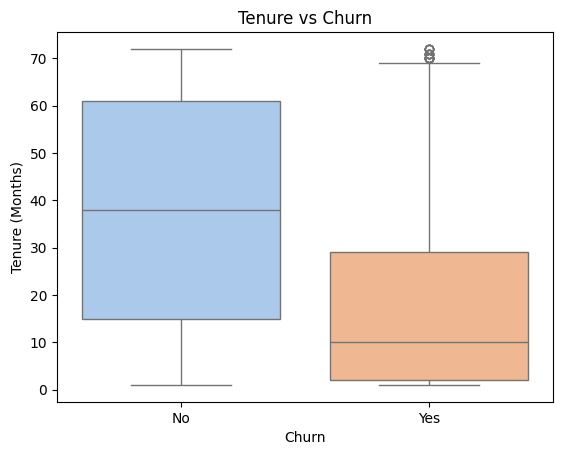

In [35]:
# Compare customer tenure between Churn categories
sns.boxplot(
  data=df,
  x="Churn",
  y="tenure",
  hue="Churn",
  palette="pastel",
  legend=False
);

# Customize the plot title and axix labels
plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

# Replace binary Churn values with readable labels
plt.xticks(ticks=[0, 1], labels=["No", "Yes"])

### Observation

Customers who stayed with the company have a median tenure of around 38 months and most of them fall between 15 and 60 months. In comparison customers who churned have a much lower median tenure of about 10 months with most customers staying for only 2 to 29 months. Overall Churn is more common among customer with shorter tenure but this only shows a relationship between tenure and Churn and doesn't mean that shorter tenure directly causes Churn.

# 4.7 Contract and Churn

We compare Churn rates across month-to-month, one-year and 2-year contracts.

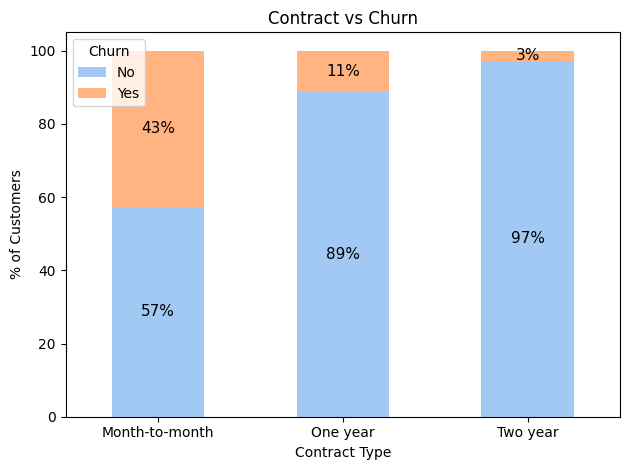

In [36]:
# Create a normalized contingency table for Contract and Churn
cross = pd.crosstab(
  df["Contract"],
  df["Churn"],
  normalize="index"
) * 100

# Plot Churn distribution within each Contract type
ax = cross.plot(
  kind="bar",
  stacked=True,
  color=sns.color_palette("pastel", 2),
)

# Add percentage labels of inside each stacked bar
for container in ax.containers:
  ax.bar_label(
    container,
    labels=[f"{x:.0f}%"  for x in container.datavalues],
    label_type="center",
    fontsize=11
  )

# Customize the plot title, axis labels and legend
ax.set_title("Contract vs Churn")
ax.set_xlabel("Contract Type")
ax.set_ylabel("% of Customers")
ax.legend(title="Churn", labels=["No", "Yes"])

# Keep x-axis labels horizontal and adjust spacing between subplots
plt.xticks(rotation=0)
plt.tight_layout();

### Observation

Churn is much higher among month-to-month customers at around 43% compared with 11% for one-year contracts and only 3% for two-year contracts which shows that customers with longer contracts are less likely to churn.

### 4.8 InternetService and Churn

We also compare the the churn rates across different internet service types including DSL, Fiber optic and customer without InternetService.

Text(0, 0.5, 'Churn Rate')

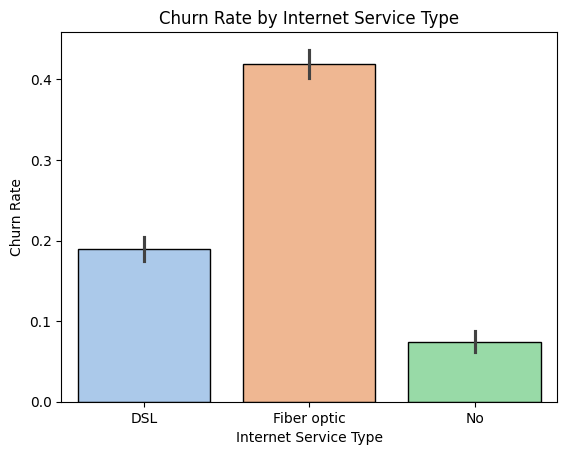

In [37]:
# Compare Churn rates across InternetService Types
sns.barplot(
  data=df,
  x="InternetService",
  y="Churn",
  hue="InternetService",
  palette="pastel",
  edgecolor="black",
  legend=False
)

# Customize the plot title and axix labels
plt.title("Churn Rate by Internet Service Type")
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Rate")

### Observation

The highest Churn Rate is seen among Fiber optic customers and this group also tends to have higher MonthlyCharges.

### 4.9 MonthlyCharges and Churn

we also compare MonthlyCharges between customers who churned also those who stayed.

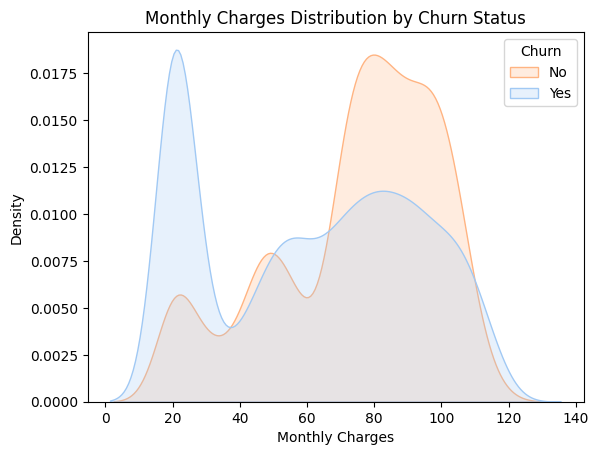

In [38]:
# Plot MonthlyCharges distribution by Churn status
sns.kdeplot(
  data=df,
  x="MonthlyCharges",
  hue="Churn",
  palette="pastel",
  common_norm=False,
  fill=True,
)

# Customize the plot title, axis labels and legend
plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")

# seaborn orders the hue legend by value (0="No" first, 1="Yes" second) —
# labels here need to follow that same order or they end up describing the
# wrong color
plt.legend(title="Churn", labels=["No", "Yes"])

### Observation

Customers who churned generally had higher MonthlyCharges with most values falling between 75 to 105 while customers who stayed had a clear concentration around 20 to 30 along with a wider range of higher charges Overall customers with higher MonthlyCharges were more likely to churn which also matches our earlier InternetService analysis where Fiber optic customers had both higher MonthllyCharges and higher Churn Rates.

### 4.10 TotalCharges and  Churn

we also compare TotalCharges between customers who churned also those who stayed.

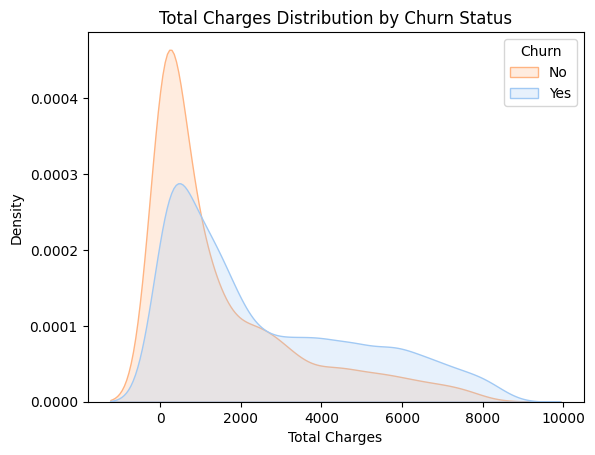

In [39]:
# Create TotalCharges distribution by Churn status
sns.kdeplot(
  data=df,
  x="TotalCharges",
  hue="Churn",
  palette="pastel",
  common_norm=False,
  fill=True
)

# Customize the plot title, axis labels and legend
plt.title("Total Charges Distribution by Churn Status")
plt.xlabel("Total Charges")
plt.ylabel("Density")
plt.legend(title="Churn", labels=["No", "Yes"])

### Observation

Customers who churned mostly have lower TotalCharges but this is also related to tenure because customers who stay for a shorter time have less time to build up their TotalCharges.

### 4.11 SeniorCitizen and Churn

Finally, we compare the Churn rates of senior and non-senior customers where senior customers make up only around 16% of the dataset so the difference should be interpreted with that in mind.

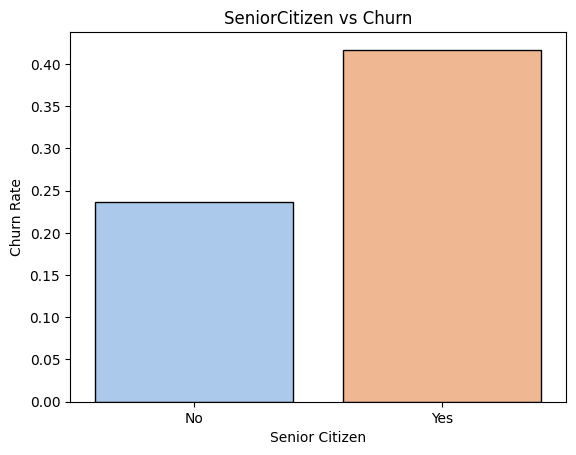

In [40]:
# Compare Churn rates between senior and non-senior customers
sns.barplot(
  data=df,
  x="SeniorCitizen",
  y="Churn",
  hue="SeniorCitizen",
  palette="pastel",
  edgecolor="black",
  legend=False,
  errorbar=None
);

# Customize the plot title and axis labels
plt.title("SeniorCitizen vs Churn")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate")
plt.xticks(ticks=[0, 1], labels=["No", "Yes"]);

### Observation

Senior customers are fewer in the dataset but they show a higher Churn Rate with around 42% of senior customers churning compared with about 24% of non-senior customers. This shows that SeniorCitizen has a noticable relationship with Churn but the plot alone doesn't explain why this difference exists.

### 4.12 Correlation Matrix

Text(0.5, 1.0, 'Correlation Matrix of Numerical Features and Churn')

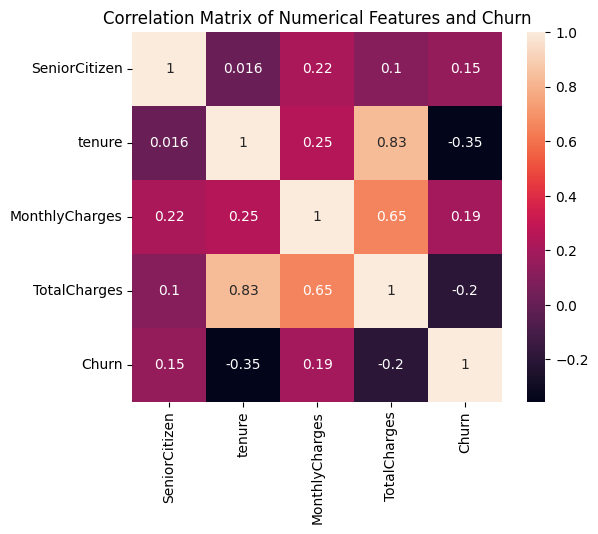

In [41]:
# Calculate the correlation matrix for numerical features
corr_matrix = df.corr(numeric_only=True)

# Visualize the correlation matrix
sns.heatmap(
  corr_matrix,
  square=True,
  annot=True
)

# Customize the plot title
plt.title("Correlation Matrix of Numerical Features and Churn")

### Observation

- `tenure` has the strongest relationship with `Churn`, with a correlation of **-0.35**. This suggests that customers who have been with the company longer are generally less likely to churn.
- `MonthlyCharges` has a weak positive correlation with `Churn` (**0.19**), so customers with higher monthly charges show a slightly higher tendency to churn.
- `TotalCharges` has a weak negative correlation with `Churn` (**-0.20**).
- `SeniorCitizen` also has a weak positive correlation with `Churn` (**0.15**).
- Overall, `tenure` shows the most noticeable relationship with churn, while the other numerical features have relatively weak correlations.
- These correlations show relationships between the variables, but they do not mean that one variable directly causes the other.

### 4.13 EDA Conclusions

- EDA shows that **Churn** is mainly related to **tenure**, **Contract**, **MonthlyCharges** and **InternetService**.

- Customers with shorter service period month to month **Contracts** and heigher **MonthlyCharges** are more likely to **Churn**.

- Some of these features are also connected with each other **TotalCharges** increases with **tenure** while heigher **MonthlyCharges** are more common among customer using **Fiber optics**

- So while building the model we should look at both individual features and how they are related to each other.

- **SeniorCitizen** also shows more relation with **Churn** but the difference is not as strong as the main factors mentioned above.